# Survival analysis

Survival families model a time-to-event response with possible right-censoring.
`mboostrs` supports the Cox proportional hazards model, three parametric
accelerated failure time (AFT) families (`Weibull`, `Loglog`, `Lognormal`), and
two rank-based families (`Gehan`, `Cindex`) that make no distributional
assumption. `CoxPH` models expose predicted survival curves via `survfit()`.

In [1]:
import numpy as np
import mboostrs as mb

rng = np.random.default_rng(42)
n = 400

## Synthetic survival data

A proportional-hazards model with two covariates and 30 % censoring:

In [2]:
x1 = rng.normal(size=n)
x2 = rng.uniform(-1, 1, size=n)
lp = 0.8 * x1 - 0.5 * x2                      # linear predictor
time = np.exp(lp + rng.exponential(scale=1.0, size=n))
status = rng.binomial(1, 0.7, size=n).astype(float)
data = {"x1": x1, "x2": x2, "time": time, "status": status}

## Cox proportional hazards (`CoxPH`)

The Cox model uses the semi-parametric proportional-hazards formulation. The
response is embedded in the formula as `Surv(time, status)`:

In [3]:
fit_cox = mb.glmboost(
    "Surv(time, status) ~ x1 + x2",
    data=data, family=mb.CoxPH(),
    control=mb.boost_control(mstop=300, nu=0.1),
)
print("mstop:", fit_cox.mstop, "| selected:", sorted(set(fit_cox.selected)))


mstop: 300 | selected: ['x1', 'x2']


### Risk and selection paths

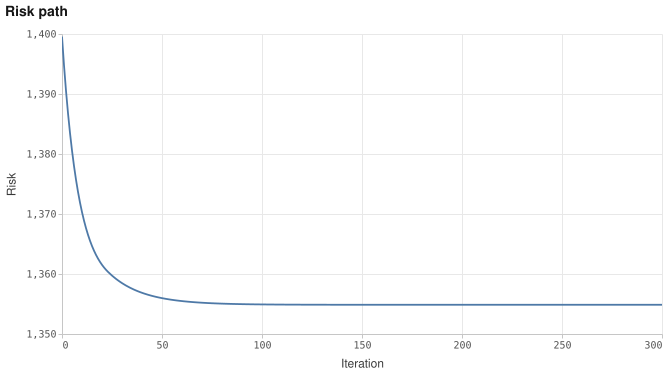

In [4]:
fit_cox.plot_risk()

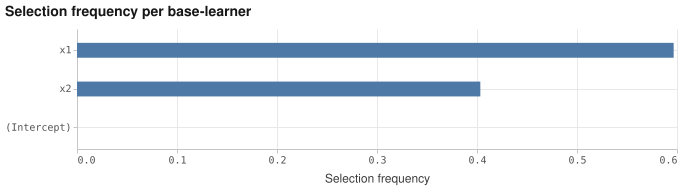

In [5]:
fit_cox.plot_selected()

The model converges within 100 iterations; `x1` and `x2` are both selected.

### Tune `mstop` with cross-validation

Because survival families have no dispersion parameter, AIC is not available
{cite}`mayr2016`. Use `cvrisk` instead:

In [6]:
cvr = fit_cox.cvrisk(type="bootstrap", B=25, seed=0)
m_opt = cvr.optimal_mstop
print(f"CoxPH optimal mstop: {m_opt}")

CoxPH optimal mstop: 99


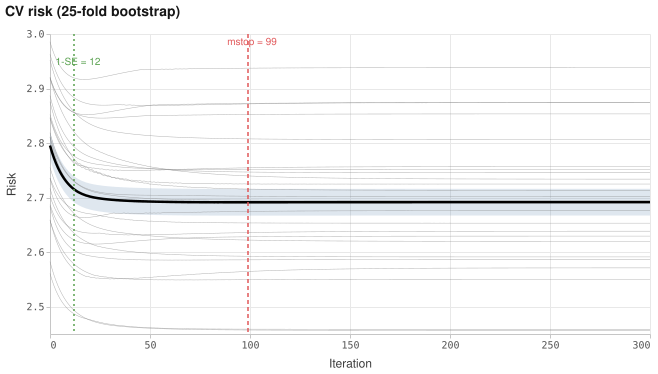

In [7]:
mb.plot.plot_cvrisk(cvr)

### Coefficients at optimal mstop

In [8]:
coefs = fit_cox[:m_opt].coef()
for k, v in coefs.items():
    if abs(v) > 1e-6:
        print(f"{k}: {v:.3f}")

(Intercept): 0.001
x1: -0.632
x2: 0.210


### Variable importance

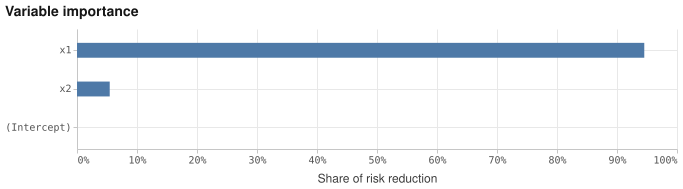

In [9]:
fit_cox[:m_opt].plot_varimp()

### Predicted survival curves (`survfit`)

`predict()` on a `CoxPH` model returns the *linear predictor* (log relative
hazard). To get an actual **survival curve** $\hat S(t \mid x)$, use `survfit()`,
which combines the Breslow baseline cumulative hazard with each subject's
relative risk — the same estimator as R's `mboost::survFit`. Without `newdata`
it returns the baseline curve; with `newdata` it returns one column per row. The
result is a dict with `time` (event times), `n_event`, and `surv` (an
`n_event × n_curves` matrix).

In [10]:
sf = fit_cox[:m_opt].survfit(
    newdata={"x1": np.array([-1.5, 1.5]), "x2": np.array([0.0, 0.0])}
)
print("event times:", len(sf["time"]), "| survival matrix:", sf["surv"].shape)
# Median survival time per profile: first t where S(t) <= 0.5.
for j, x1v in enumerate([-1.5, 1.5]):
    below = np.where(sf["surv"][:, j] <= 0.5)[0]
    med = sf["time"][below[0]] if len(below) else float("inf")
    print(f"x1={x1v:+.1f}: median survival time ≈ {med:.2f}")
# Higher x1 lengthens survival here (the data's x1 coefficient is +0.8), so the
# x1=+1.5 profile has the far larger median.

event times: 279 | survival matrix: (279, 2)
x1=-1.5: median survival time ≈ 1.47
x1=+1.5: median survival time ≈ 11.36


## Accelerated failure time models

AFT families model $\log T$ directly, with a parametric error distribution.
`mboostrs` provides `Weibull`, `Loglog`, and `Lognormal`. Positive coefficients
lengthen expected survival time (the "acceleration" factor is $e^\beta$).

### Weibull AFT

In [11]:
fit_wbl = mb.glmboost(
    "Surv(time, status) ~ x1 + x2",
    data=data, family=mb.Weibull(),
    control=mb.boost_control(mstop=300, nu=0.1),
)
print("mstop:", fit_wbl.mstop, "| selected:", sorted(set(fit_wbl.selected)))


mstop: 300 | selected: ['(Intercept)', 'x1']


In [12]:
cvr_wbl = fit_wbl.cvrisk(type="bootstrap", B=25, seed=0)
m_wbl = cvr_wbl.optimal_mstop
print(f"Weibull optimal mstop: {m_wbl}")

Weibull optimal mstop: 161


In [13]:
coefs_wbl = fit_wbl[:m_wbl].coef()
for k, v in coefs_wbl.items():
    if abs(v) > 1e-6:
        accel = np.exp(v)
        print(f"{k}: β={v:.3f}  acceleration={accel:.3f}")

(Intercept): β=-0.544  acceleration=0.581
x1: β=0.552  acceleration=1.736


### Log-logistic and log-normal

In [14]:
for name, fam in [("Loglogistic", mb.Loglog()), ("Lognormal", mb.Lognormal())]:
    fit = mb.glmboost(
        "Surv(time, status) ~ x1 + x2",
        data=data, family=fam,
        control=mb.boost_control(mstop=300, nu=0.1),
    )
    cvr = fit.cvrisk(type="bootstrap", B=25, seed=0)
    m = cvr.optimal_mstop
    coeff = fit[:m].coef()
    active = {k: round(v, 3) for k, v in coeff.items() if abs(v) > 1e-6}
    print(f"{name:14s}  optimal mstop={m:3d}  coefs={active}")

Loglogistic     optimal mstop=300  coefs={'(Intercept)': -0.244, 'x1': 0.783, 'x2': -0.367}


Lognormal       optimal mstop=100  coefs={'(Intercept)': -0.002, 'x1': 0.763, 'x2': -0.315}


/Users/fcela/src/public_github/mboostrs/python/mboostrs/glmboost.py:863: UserWarning: optimal mstop 300 is within 5% of the search cap 300; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/tmp/ipykernel_68027/1509557920.py:7: RuntimeWarning: the cross-validated risk is still falling at mstop=300, the largest iteration evaluated, so the reported optimal_mstop=300 is where the path stopped rather than where the risk turns. Refit with a larger mstop and cross-validate again on the same folds: `model.continue_to(600)` then `cvrisk(folds=...)`. (`continue_to` resumes the retained gradient where the fit kept one, and otherwise costs a full path; `parity_notes(include_global=True)` says which routes resume.)
  cvr = fit.cvrisk(type="bootstrap", B=25, seed=0)


## Rank-based survival: `Gehan` and `Cindex`

The AFT families above assume a parametric error distribution. Two families
instead optimize a **rank** objective, making no distributional assumption:

- **`Gehan`** minimizes a censored rank statistic (an AFT model fit by the
  Gehan–Wilcoxon score). Its intercept is not identifiable — the loss depends
  only on residual *differences* — so `mboostrs` fixes `offset = 0` and fitted
  values match R up to an additive constant. Coefficients, selection, and risk
  match exactly.
- **`Cindex(sigma)`** maximizes a smoothed, IPCW-weighted estimate of Uno's
  concordance index (the probability that the model ranks a random comparable
  pair correctly). `sigma` (default `0.1`) is the smoothing scale. It needs
  `{0,1}` weights, so `cvrisk`/`stabsel` with subsampling folds work.

Both take the same `Surv(time, status)` response. Their negative gradients are
sums over observation pairs ($O(n^2)$ per iteration).

In [15]:
# Gehan: AFT rank loss (offset fixed at 0; compare relative coefficients)
fit_gehan = mb.glmboost(
    "Surv(time, status) ~ x1 + x2",
    data=data, family=mb.Gehan(),
    control=mb.boost_control(mstop=200, nu=0.1),
)
print("Gehan coefs:", {k: round(v, 3) for k, v in fit_gehan.coef().items()
                       if abs(v) > 1e-6})

# Cindex: smoothed IPCW concordance; supports subsampling cvrisk
fit_cindex = mb.glmboost(
    "Surv(time, status) ~ x1 + x2",
    data=data, family=mb.Cindex(sigma=0.1),
    control=mb.boost_control(mstop=200, nu=0.1),
)
cv_c = fit_cindex.cvrisk(type="subsampling", B=10, seed=0)
print(f"Cindex risk: start={fit_cindex.risk_[0]:.3f} end={fit_cindex.risk_[-1]:.3f}"
      f"  |  cvrisk optimal mstop={cv_c.optimal_mstop}")

# IPCW weights (inverse probability of censoring) are the building block Cindex
# uses internally, and are exposed directly for custom weighting schemes:
w = mb.ipc_weights(data["time"], data["status"], maxweight=5.0)
print(f"ipc_weights: {int((w == 0).sum())} censored obs get weight 0; "
      f"max weight = {w.max():.2f}")

Gehan coefs: {'(Intercept)': -0.005, 'x1': 0.789, 'x2': -0.444}


Cindex risk: start=-0.500 end=-0.588  |  cvrisk optimal mstop=200
ipc_weights: 121 censored obs get weight 0; max weight = 5.00


/Users/fcela/src/public_github/mboostrs/python/mboostrs/glmboost.py:863: UserWarning: optimal mstop 200 is within 5% of the search cap 200; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/tmp/ipykernel_68027/4040882126.py:16: RuntimeWarning: the cross-validated risk is still falling at mstop=200, the largest iteration evaluated, so the reported optimal_mstop=200 is where the path stopped rather than where the risk turns. Refit with a larger mstop and cross-validate again on the same folds: `model.continue_to(400)` then `cvrisk(folds=...)`. (`continue_to` resumes the retained gradient where the fit kept one, and otherwise costs a full path; `parity_notes(include_global=True)` says which routes resume.)
  cv_c = fit_cindex.cvrisk(type="subsampling", B=10, seed=0)


## Smooth survival effects with `gamboost`

Replace linear terms with P-splines to capture nonlinear effects:

In [16]:
fit_gam = mb.gamboost(
    "Surv(time, status) ~ bbs(x1, df=4) + bbs(x2, df=4)",
    data=data, family=mb.CoxPH(),
    control=mb.boost_control(mstop=300, nu=0.1),
)
print("mstop:", fit_gam.mstop, "| selected:", sorted(set(fit_gam.selected)))


mstop: 300 | selected: ['x1', 'x2']


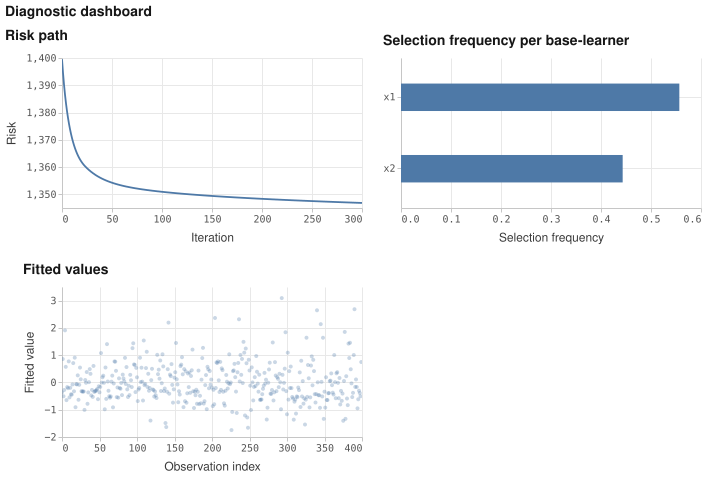

In [17]:
mb.plot.plot_diagnostics(fit_gam)

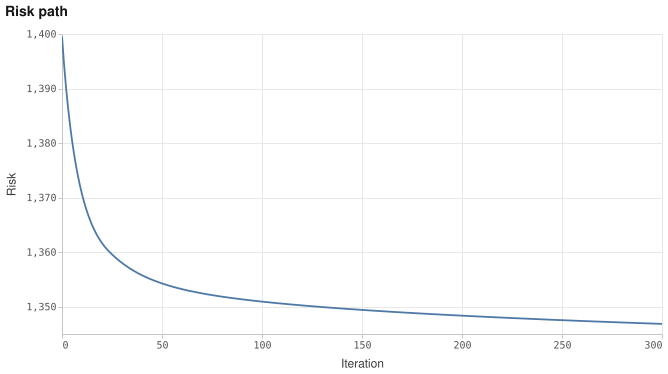

In [18]:
fit_gam.plot_risk()

## Follow-up time as a predictor

`bbs(time, by=x1)` uses each subject's eventual event or censoring time as
a baseline predictor. It does not evaluate `x1` at changing risk-set times,
and it uses information determined after follow-up begins. A time-dependent
Cox effect needs start-stop data and is not implemented. Selection of
`bbs(time, by=x1)` would show association with observed follow-up time under a
misspecified predictor construction; it is not a test of proportional hazards.
Use a survival package with start-stop intervals or another explicit risk-set
representation when the scientific question needs time-dependent covariates or
coefficients. The following formula is shown as a counterexample and is not fitted:

In [19]:
invalid_time_dependent_formula = (
    "Surv(time, status) ~ bols(x1) + bols(x2) + bbs(time, by=x1, df=4)"
)
invalid_time_dependent_formula

'Surv(time, status) ~ bols(x1) + bols(x2) + bbs(time, by=x1, df=4)'

In [20]:
# Use software with start-stop risk sets for a time-dependent coefficient.
"start-stop survival support required"

'start-stop survival support required'

## Example: WPBC time to recurrence

The Wisconsin Prognostic Breast Cancer (`wpbc`) data records time to
recurrence after surgery, with four tumor measurements as predictors. Fit
`CoxPH` and all three AFT families to the same predictors and compare:

In [21]:
wpbc = mb.datasets.wpbc().drop_nulls(subset=["pnodes"])
wpbc_data = {c: wpbc[c].to_numpy()
             for c in ["time", "status", "tsize", "pnodes", "mean_radius", "mean_texture"]}
wpbc_formula = "Surv(time, status) ~ tsize + pnodes + mean_radius + mean_texture"

wpbc_results = {}
for name, fam in [("CoxPH", mb.CoxPH()), ("Weibull", mb.Weibull()),
                   ("Loglog", mb.Loglog()), ("Lognormal", mb.Lognormal())]:
    fit = mb.glmboost(wpbc_formula, data=wpbc_data, family=fam,
                       control=mb.boost_control(mstop=200, nu=0.1))
    wpbc_results[name] = {k: round(v, 4) for k, v in fit.coef().items()
                          if abs(v) > 1e-6 and k != "(Intercept)"}

import polars as pl
pl.DataFrame(wpbc_results).fill_null(0.0).fill_nan(0.0)


CoxPH,Weibull,Loglog,Lognormal
struct[4],struct[3],struct[3],struct[3]
"{0.0679,0.0349,0.1342,-0.0065}","{-0.0609,-0.0284,-0.1368}","{-0.0703,-0.0426,-0.1542}","{-0.0392,-0.0412,-0.1437}"


The sign convention differs by construction: `CoxPH` models the *hazard*, so
a positive coefficient means faster recurrence, while the AFT families model
$\log(\text{time})$ directly, so a positive coefficient means *longer*
survival. All four families agree in substance: larger tumor size (`tsize`),
more positive lymph nodes (`pnodes`), and larger `mean_radius` all raise the
hazard (`CoxPH`, positive) and equivalently shorten the AFT time scale (the
other three, negative).

## Survival models in R

The R binding supports `CoxPH`, `Weibull`, `Loglog`, `Lognormal`, and
`LogNormalLSS`, `LogLogLSS`, `WeibullLSS` (LSS families) with the same
`Surv(time, status)` formula syntax:

```r
library(mboostrs)

fit_cox <- glmboost(Surv(time, status) ~ x1 + x2, data = data,
                    family = CoxPH(), control = boost_control(300, 0.1))

cvr <- cvrisk(fit_cox, type = "bootstrap", B = 25, seed = 0)
m_opt <- mstop(cvr)
coef(fit_cox[m_opt])
```

## See also

- [](../methodology/survival) — the Cox, Weibull, Log-logistic, and Lognormal
  families' losses, gradients, and offsets.
- [](../methodology/model_selection) — why AIC is invalid for survival models
  and how bootstrap cvrisk replaces it.
- [](../implementation/lss_engine) — the LSS engine that powers the
  LogNormalLSS, LogLogLSS, and WeibullLSS families.
- [](../implementation/parity_and_bugs) — documented differences from R's
  survival families (CoxPH tied-handling, offset coding).

```{bibliography}
:filter: docname in docnames
```